## Uploading the file

*Data read from `../data/` (no upload needed outside Colab).*

## Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## Importing the CSV file

In [2]:
dataset = pd.read_csv('../data/Mall_Customers.csv')

## Dataset Information

In [3]:
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


## Counting the number of nan values

In [4]:
dataset.isna().sum()

CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

## Observing the data

In [5]:
dataset.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


## Select Numerical values

In [6]:
X = dataset.iloc[:,[2,3,4]].values
X

array([[ 19,  15,  39],
       [ 21,  15,  81],
       [ 20,  16,   6],
       [ 23,  16,  77],
       [ 31,  17,  40],
       [ 22,  17,  76],
       [ 35,  18,   6],
       [ 23,  18,  94],
       [ 64,  19,   3],
       [ 30,  19,  72],
       [ 67,  19,  14],
       [ 35,  19,  99],
       [ 58,  20,  15],
       [ 24,  20,  77],
       [ 37,  20,  13],
       [ 22,  20,  79],
       [ 35,  21,  35],
       [ 20,  21,  66],
       [ 52,  23,  29],
       [ 35,  23,  98],
       [ 35,  24,  35],
       [ 25,  24,  73],
       [ 46,  25,   5],
       [ 31,  25,  73],
       [ 54,  28,  14],
       [ 29,  28,  82],
       [ 45,  28,  32],
       [ 35,  28,  61],
       [ 40,  29,  31],
       [ 23,  29,  87],
       [ 60,  30,   4],
       [ 21,  30,  73],
       [ 53,  33,   4],
       [ 18,  33,  92],
       [ 49,  33,  14],
       [ 21,  33,  81],
       [ 42,  34,  17],
       [ 30,  34,  73],
       [ 36,  37,  26],
       [ 20,  37,  75],
       [ 65,  38,  35],
       [ 24,  38

## K-means

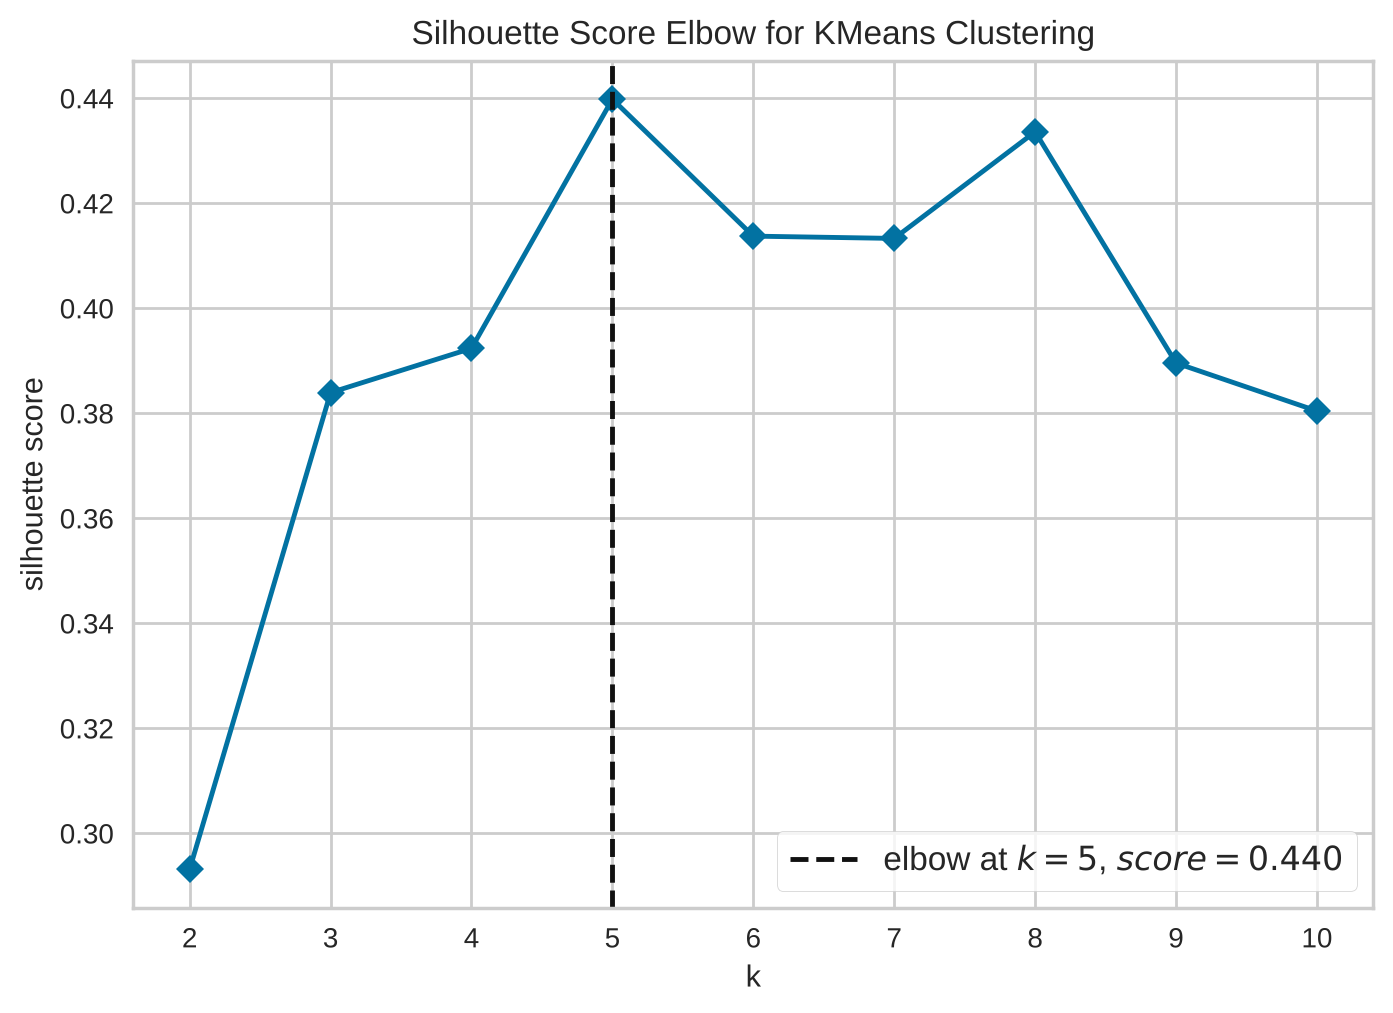

<Axes: title={'center': 'Silhouette Score Elbow for KMeans Clustering'}, xlabel='k', ylabel='silhouette score'>

In [7]:
from sklearn.cluster import KMeans

model = KMeans()

from yellowbrick.cluster import KElbowVisualizer

visualizer = KElbowVisualizer(model, k = (2,11),metric='silhouette',timings=False)

visualizer.fit(X)

visualizer.show()


## K-means++

In [8]:
kmeansmodel = KMeans(n_clusters=5, init='k-means++',random_state=42)
y_kmeans = kmeansmodel.fit_predict(X)

In [9]:
y_kmeans

array([2, 2, 0, 2, 0, 2, 0, 2, 0, 2, 0, 2, 0, 2, 0, 2, 0, 2, 0, 2, 0, 2,
       0, 2, 0, 2, 0, 2, 0, 2, 0, 2, 0, 2, 0, 2, 0, 2, 0, 2, 0, 2, 0, 2,
       0, 2, 0, 0, 0, 0, 0, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 0, 0, 0, 2,
       0, 0, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 2, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 4, 0, 0, 0, 0, 0, 0,
       0, 4, 0, 0, 0, 4, 0, 0, 0, 0, 4, 0, 4, 4, 3, 4, 3, 4, 3, 4, 3, 4,
       3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4,
       3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4, 3, 4,
       3, 4, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1,
       3, 1], dtype=int32)

In [10]:
dataset['y_means'] = y_kmeans+1
dataset.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),y_means
0,1,Male,19,15,39,3
1,2,Male,21,15,81,3
2,3,Female,20,16,6,1
3,4,Female,23,16,77,3
4,5,Female,31,17,40,1


## Scatter Plot

## Code Explantion:

#### y_kmeans is the final model.
#### scatter function is a function from Matplotlib is used to create a scatter plot.
#### X[y_kmeans == 4, 0]: X is the dataset used for clustering, containing features like Annual Income and Spending Score.
#### y_kmeans == 4 creates a Boolean mask that selects only the rows in X where y_kmeans
#### (the predicted cluster labels from the model) is 4,
#### meaning those points are classified into Cluster 4.
#### X[y_kmeans == 4, 0] extracts the first column (index 0) of X for Cluster 4 data points,
#### which corresponds to Annual Income.
#### X[y_kmeans == 4, 1]:
#### This extracts the second column (index 1) of X for Cluster 4 data points,
#### which corresponds to Spending Score
#### s = 100, parameter set size of each point

In [11]:
T = np.array([[1,2,3],
              [4,5,6]])

In [12]:
T[:,2]

array([3, 6])

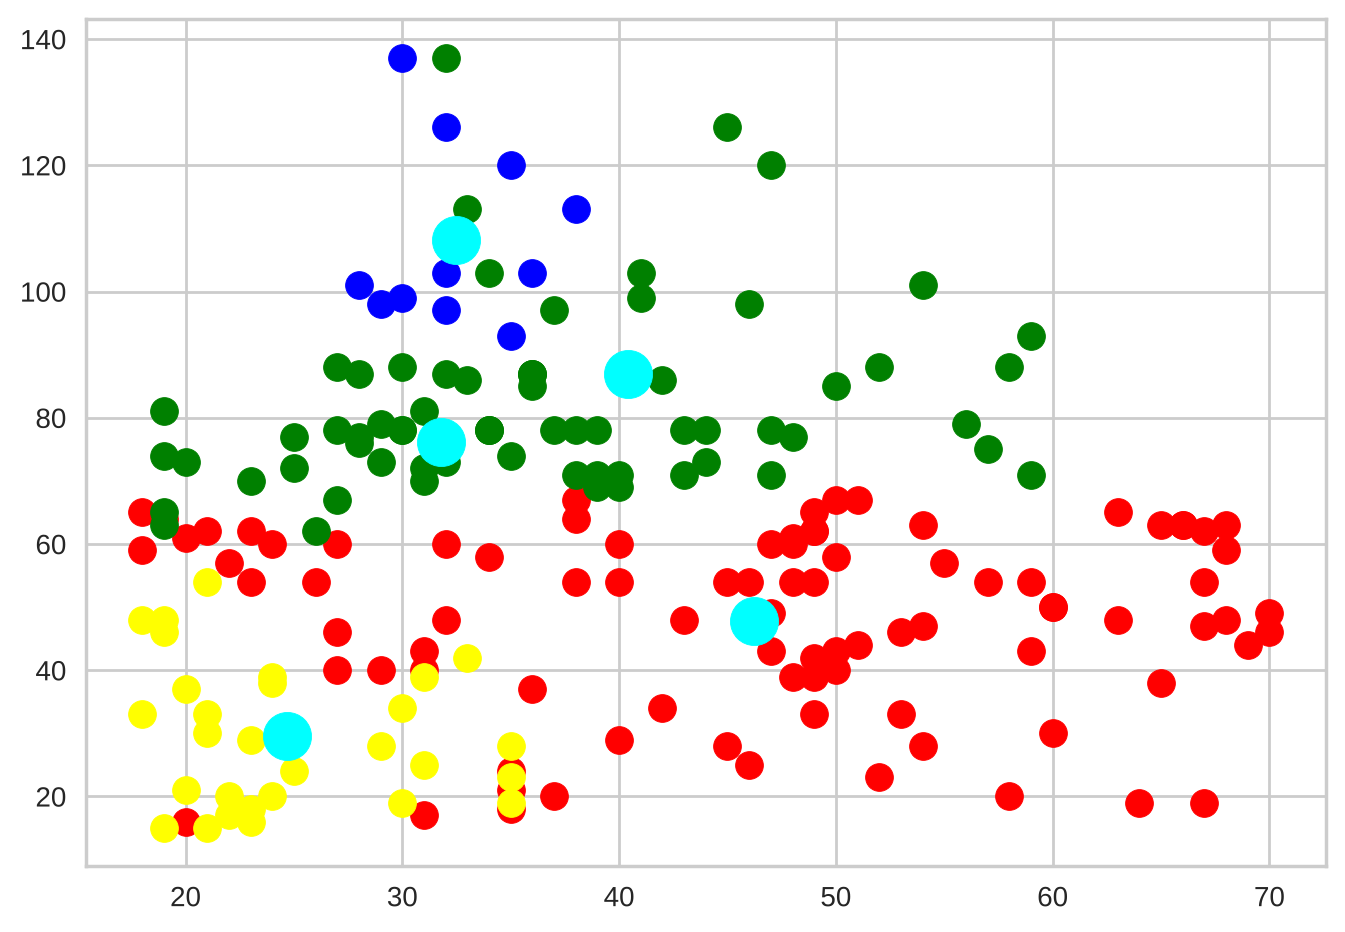

In [13]:
plt.scatter(X[y_kmeans == 0,0],X[y_kmeans==0,1],
            s=100,c='red',label='cluster 1')
plt.scatter(X[y_kmeans == 1,0],X[y_kmeans==1,1],
            s=100,c='blue',label='cluster 2')
plt.scatter(X[y_kmeans == 2,0],X[y_kmeans==2,1],
            s=100,c='yellow',label='cluster 3')
plt.scatter(X[y_kmeans == 3,0],X[y_kmeans==3,1],
            s=100,c='green',label='cluster 4')
plt.scatter(X[y_kmeans == 4,0],X[y_kmeans==4,1],
            s=100,c='green',label='cluster 5')
plt.scatter(kmeansmodel.cluster_centers_[:,0],
            kmeansmodel.cluster_centers_[:,1],
            s=300,c='cyan',label='Centroids')

## 3D plot

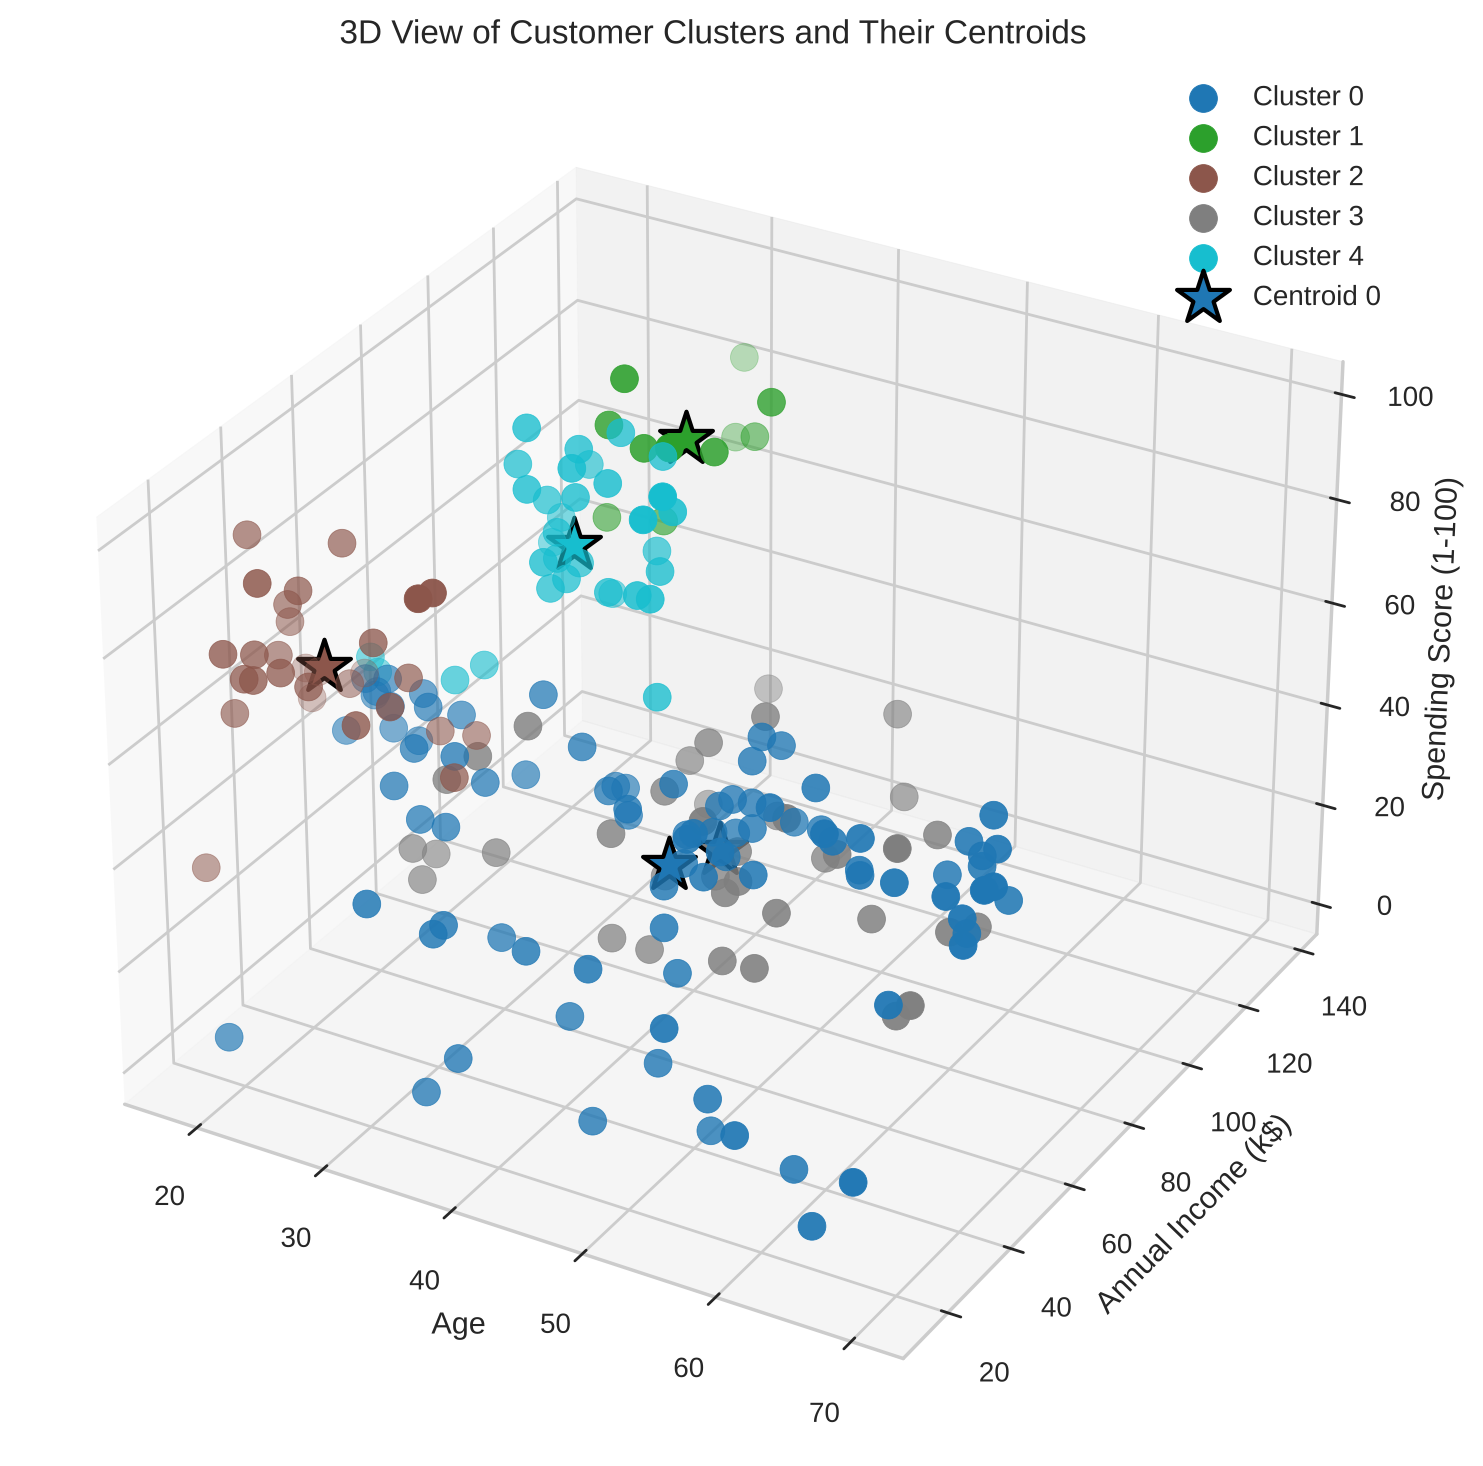

In [14]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import numpy as np

# Create a new figure for the 3D plot
fig = plt.figure(figsize=(12, 9))
ax = fig.add_subplot(111, projection='3d')

# Get the exact number of clusters from the model
n_clusters = kmeansmodel.n_clusters

# Generate distinct colors for each cluster dynamically
colors = plt.get_cmap('tab10', n_clusters)  # plt.cm.get_cmap no longer exists in matplotlib >= 3.9

# Plot the data points for each of the 4 clusters
for i in range(n_clusters):
    ax.scatter(X[y_kmeans == i, 0],  # Age
               X[y_kmeans == i, 1],  # Annual Income
               X[y_kmeans == i, 2],  # Spending Score
               s=100,
               color=colors(i),
               label=f'Cluster {i}')

# Plot all 4 corresponding centroids
centroids = kmeansmodel.cluster_centers_
for i in range(n_clusters):
    ax.scatter(centroids[i, 0],
               centroids[i, 1],
               centroids[i, 2],
               s=400,
               color=colors(i),
               marker='*',
               edgecolors='black',
               linewidths=1.5,
               label=f'Centroid {i}' if i == 0 else "")  # Single label for legend clarity

# Label the 3D axes
ax.set_title('3D View of Customer Clusters and Their Centroids')
ax.set_xlabel('Age')
ax.set_ylabel('Annual Income (k$)')
ax.set_zlabel('Spending Score (1-100)')
ax.legend()
plt.show()